# Volume 2, Appendix E: The Spectral Theorem and Its Relatives (Python companion)

Exercises first, solutions at the end. We test the min-max theorem against random subspaces, draw interlacing patterns and build a matrix with prescribed interlacing spectra, check Weyl's and Hoffman–Wielandt's inequalities, run Horn's rotation algorithm to build symmetric matrices with a prescribed diagonal and spectrum, and end with a glimpse of random matrix theory. We use `numpy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import itertools, math
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(5)
def rand_herm(n, complex_=True):
    G = rng.standard_normal((n, n)) + (1j * rng.standard_normal((n, n)) if complex_ else 0)
    return (G + G.conj().T) / 2
eig = lambda A: np.sort(np.linalg.eigvalsh(A))[::-1]        # decreasing, as in the chapter

## Exercises

**P5.1 (★) Normal or not.** Build a random normal matrix as $UDU^*$ and check that $AA^*=A^*A$. For a random non-normal matrix, compute the *departure from normality* $\|A\|_F^2-\sum|\lambda_i|^2$, which is the squared Frobenius norm of the strictly upper part of any Schur form. Why is it non-negative, and zero exactly for normal matrices (Theorem 5.2)?

**P5.2 (★) Min-max against random subspaces.** For a random Hermitian $8\times8$ matrix and $k=3$, draw $2000$ random $3$-dimensional subspaces $W$ and compute $\min_WR_A$ (the smallest eigenvalue of the compression to $W$). Check that all values are at most $\lambda_3$ (Theorem 5.4) and plot their histogram. How close do random subspaces come?

**P5.3 (★★) Interlacing both ways.** Check Theorem 5.5 for all corners of a random $10\times10$ symmetric matrix, and for compressions to random subspaces of every dimension. Then implement Exercise 5.11: given strictly interlacing $\lambda$ and $\mu$, build the bordered matrix and verify its spectrum.

**P5.4 (★★) Weyl and Hoffman–Wielandt.** For random Hermitian $A,B$ of size $6$, check all Weyl inequalities $\lambda_{i+j-1}(A+B)\le\lambda_i(A)+\lambda_j(B)$ (Theorem 5.6). For random normal $A,B$, find the best matching of eigenvalues by brute force over all $720$ permutations and check Theorem 5.11. Then test the non-normal pair of Exercise 5.5.

**P5.5 (★★★) Horn's algorithm.** Implement the proof of Theorem 5.10 as a function `horn(d, lam)` returning a real symmetric matrix with diagonal $d$ and eigenvalues $\lambda$ whenever $d\prec\lambda$. Test it on $200$ random majorised pairs (a random doubly stochastic matrix applied to $\lambda$ gives a majorised $d$, by the proof of Theorem 5.9), and on the matrix of Exercise 5.2.

**P5.6 (★★) A first look at random matrices.** Plot the histogram of the eigenvalues of a random real symmetric $n\times n$ matrix with independent $N(0,1)$ entries (up to symmetry), scaled by $\sqrt n$, for $n=1000$. Compare with Wigner's semicircle density $\frac1{2\pi}\sqrt{4-x^2}$. How does the largest eigenvalue compare with the bounds of Corollary 5.7?

## Solutions

### P5.1
**How to find it.** In a Schur form $T=U^*AU$, $\|A\|_F^2=\|T\|_F^2=\sum|t_{ii}|^2+\sum_{i<j}|t_{ij}|^2$, and the $t_{ii}$ are the eigenvalues. So the departure is the strictly upper part, non-negative, and by the proof of Theorem 5.2 it vanishes exactly when $T$ is diagonal, that is when $A$ is normal.

In [2]:
n = 6
Q, _ = np.linalg.qr(rng.standard_normal((n, n)) + 1j * rng.standard_normal((n, n)))
D = np.diag(rng.standard_normal(n) + 1j * rng.standard_normal(n))
A_norm = Q @ D @ Q.conj().T
A_rand = rng.standard_normal((n, n))
for name, A in [("UDU*", A_norm), ("random", A_rand)]:
    lam = np.linalg.eigvals(A)
    print(f"{name:7s} ||AA*-A*A|| = {np.linalg.norm(A @ A.conj().T - A.conj().T @ A):.2e}   "
          f"departure = {abs(np.linalg.norm(A)**2 - np.sum(np.abs(lam)**2)):.4f}")

UDU*    ||AA*-A*A|| = 1.84e-15   departure = 0.0000
random  ||AA*-A*A|| = 1.23e+01   departure = 8.9827


### P5.2
**How to find it.** A random subspace is the column space of a random $8\times3$ matrix; orthonormalise it with $QR$, then $\min_WR_A=\lambda_{\min}(Q^*AQ)$.

lambda_3 = 1.6852   max over random W of min R_A = 0.3345   all below: True


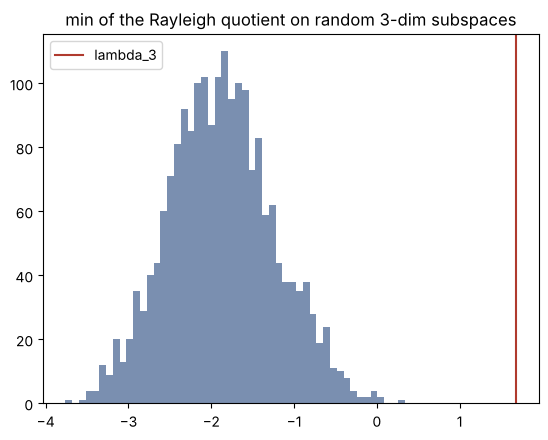

In [3]:
A = rand_herm(8); lam = eig(A)
vals = []
for _ in range(2000):
    Qw, _ = np.linalg.qr(rng.standard_normal((8, 3)) + 1j * rng.standard_normal((8, 3)))
    vals.append(np.linalg.eigvalsh(Qw.conj().T @ A @ Qw).min())
vals = np.array(vals)
print("lambda_3 =", lam[2].round(4), "  max over random W of min R_A =", vals.max().round(4), "  all below:", (vals <= lam[2] + 1e-12).all())
plt.hist(vals, bins=50, color='#7a8fb0'); plt.axvline(lam[2], color='#b03a2e', label='lambda_3')
plt.legend(); plt.title("min of the Rayleigh quotient on random 3-dim subspaces"); plt.show()

Random subspaces are poor: the max-min is attained only near the span of the top three eigenvectors, a set of tiny probability. Optimisation, not sampling, finds eigenvalues.

### P5.3
**How to find it.** Compressions to random $m$-dimensional subspaces are $Q^*AQ$ with $Q$ having orthonormal columns. For the bordered matrix, the solution of Exercise 5.11 gives $c=\sum\lambda_j-\sum\mu_i$ and $b_i^2=-f(\mu_i)/g'(\mu_i)$.

In [4]:
n = 10; A = rand_herm(n, complex_=False); lam = eig(A); ok = True
for m in range(1, n + 1):
    for B in [A[:m, :m]] + [(lambda Q: Q.T @ A @ Q)(np.linalg.qr(rng.standard_normal((n, m)))[0]) for _ in range(20)]:
        mu = eig(B)
        ok &= all(lam[k] + 1e-10 >= mu[k] >= lam[k + n - m] - 1e-10 for k in range(m))
print("interlacing holds for all corners and random compressions:", ok)

def bordered(lam, mu):
    lam, mu = np.asarray(lam, float), np.asarray(mu, float)
    f = lambda x: np.prod(x - lam)
    gp = lambda i: np.prod([mu[i] - mu[l] for l in range(len(mu)) if l != i])
    b = np.sqrt([-f(mu[i]) / gp(i) for i in range(len(mu))])
    M = np.diag(np.append(mu, lam.sum() - mu.sum())); M[:-1, -1] = b; M[-1, :-1] = b
    return M

lam6 = np.array([5.0, 3.0, 1.5, 0.0, -2.0, -4.0]); mu5 = np.array([4.0, 2.0, 1.0, -1.0, -3.0])
M = bordered(lam6, mu5)
print("bordered matrix spectrum:", eig(M).round(10), " target:", lam6)

interlacing holds for all corners and random compressions: True
bordered matrix spectrum: [ 5.   3.   1.5  0.  -2.  -4. ]  target: [ 5.   3.   1.5  0.  -2.  -4. ]


### P5.4
**How to find it.** Loop over all valid $(i,j)$. For Hoffman–Wielandt, `itertools.permutations` of $6$ objects is fast enough.

In [5]:
A, B = rand_herm(6), rand_herm(6)
a, b, s = eig(A), eig(B), eig(A + B)
viol = [(i, j) for i in range(1, 7) for j in range(1, 7) if i + j - 1 <= 6 and s[i + j - 2] > a[i - 1] + b[j - 1] + 1e-12]
print("Weyl inequalities checked:", sum(1 for i in range(1, 7) for j in range(1, 7) if i + j <= 7), " violations:", viol)

def rand_normal(n):
    Q, _ = np.linalg.qr(rng.standard_normal((n, n)) + 1j * rng.standard_normal((n, n)))
    return Q @ np.diag(rng.standard_normal(n) + 1j * rng.standard_normal(n)) @ Q.conj().T

for trial in range(3):
    A, B = rand_normal(6), rand_normal(6)          # B must be normal too: A + small normal is not
    al, be = np.linalg.eigvals(A), np.linalg.eigvals(B)
    best = min(sum(abs(al[i] - be[p[i]])**2 for i in range(6)) for p in itertools.permutations(range(6)))
    print(f"best matching {best:.4f}  <=  ||A-B||_F^2 = {np.linalg.norm(A - B)**2:.4f}")

eps = 1e-4
A2, E2 = np.array([[0, 1], [0, 0.]]), np.array([[0, 0], [eps, 0.]])
print("non-normal: eigenvalues of A+E =", np.linalg.eigvals(A2 + E2), " moved by", math.sqrt(eps), ">> ||E|| =", eps)

Weyl inequalities checked: 21  violations: []
best matching 8.5605  <=  ||A-B||_F^2 = 24.6500
best matching 4.7309  <=  ||A-B||_F^2 = 22.3488
best matching 15.5305  <=  ||A-B||_F^2 = 36.0080
non-normal: eigenvalues of A+E = [ 0.01+0.j -0.01+0.j]  moved by 0.01 >> ||E|| = 0.0001


### P5.5
**How to find it.** Follow the induction literally: sort, find $k$ with $\lambda_k\ge d_1\ge\lambda_{k+1}$, rotate, move index $k$ to the front, recurse on the remaining diagonal block, and undo the sorting at the end. Keep track of the orthogonal matrix rather than the conjugated one: we want $Q$ with $\operatorname{diag}(Q\Lambda Q^{\mathsf T})=d$.

In [6]:
def horn_Q(d, lam):
    # orthogonal Q with diag(Q diag(lam) Q^T) = d, for d and lam decreasing with d majorised by lam
    n = len(d)
    if n == 1:
        return np.eye(1)
    d1 = d[0]
    k = next(i for i in range(n - 1) if lam[i] >= d1 - 1e-12 and d1 >= lam[i + 1] - 1e-12)
    c2 = 1.0 if lam[k] == lam[k + 1] else (d1 - lam[k + 1]) / (lam[k] - lam[k + 1])
    c, s = math.sqrt(min(max(c2, 0), 1)), math.sqrt(1 - min(max(c2, 0), 1))
    G = np.eye(n); G[k, k], G[k, k + 1], G[k + 1, k], G[k + 1, k + 1] = c, -s, s, c
    order = [k] + [i for i in range(n) if i != k]        # move index k to the front
    P = np.eye(n)[order]
    lam2 = lam.copy(); lam2[k + 1] = lam[k] + lam[k + 1] - d1
    lam_rest = np.delete(lam2, k)
    Qr = horn_Q(d[1:], lam_rest)
    return np.block([[np.eye(1), np.zeros((1, n - 1))], [np.zeros((n - 1, 1)), Qr]]) @ P @ G

def horn(d, lam):
    d, lam = np.asarray(d, float), np.asarray(lam, float)
    od = np.argsort(-d); ls = np.sort(lam)[::-1]
    Q = horn_Q(d[od], ls)
    M = Q @ np.diag(ls) @ Q.T
    inv = np.argsort(od)
    return M[np.ix_(inv, inv)]

def random_doubly_stochastic(n, steps=30):
    S = np.zeros((n, n)); w = rng.dirichlet(np.ones(steps))
    for wt in w: S += wt * np.eye(n)[rng.permutation(n)]
    return S

worst = 0
for trial in range(200):
    n = int(rng.integers(2, 9)); lam = rng.standard_normal(n)
    d = random_doubly_stochastic(n) @ lam
    M = horn(d, lam)
    worst = max(worst, np.abs(np.diag(M) - d).max(), np.abs(np.sort(np.linalg.eigvalsh(M)) - np.sort(lam)).max(),
                np.abs(M - M.T).max())
print("200 random tests, worst error:", f"{worst:.1e}")
print(horn([2, 1, 0], [3, 0, 0]).round(4))

200 random tests, worst error: 3.1e-15
[[2.     1.4142 0.    ]
 [1.4142 1.     0.    ]
 [0.     0.     0.    ]]


### P5.6
**How to find it.** `eigvalsh` on a $1000\times1000$ matrix takes a fraction of a second. By Corollary 5.7, all eigenvalues lie in $[-\|A\|,\|A\|]$, which says nothing new; the real information is that, after scaling by $\sqrt n$, the spectrum fills $[-2,2]$ with a definite shape.

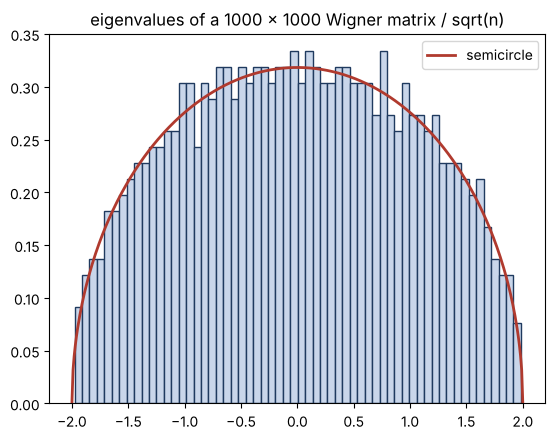

largest scaled eigenvalue: 1.9822  (tends to 2)


In [7]:
n = 1000
G = rng.standard_normal((n, n)); A = (G + G.T) / math.sqrt(2)
ev = np.linalg.eigvalsh(A) / math.sqrt(n)
x = np.linspace(-2, 2, 400)
plt.hist(ev, bins=60, density=True, color='#c9d6ea', edgecolor='#1f3a5f')
plt.plot(x, np.sqrt(4 - x**2) / (2 * math.pi), color='#b03a2e', lw=2, label='semicircle')
plt.legend(); plt.title("eigenvalues of a 1000 x 1000 Wigner matrix / sqrt(n)"); plt.show()
print("largest scaled eigenvalue:", ev.max().round(4), " (tends to 2)")

Wigner found the semicircle in 1955 while modelling the energy levels of heavy nuclei, the physical spectra of Hilbert's metaphor again. Volume 11 proves the semicircle law and meets the same statistics in the zeros of the Riemann zeta function.